# CS164 — Assignment 2: Unconstrained & Equality-Constrained Optimization

**Python notebook.** Reproduces the numerical optimization and runtime comparisons supporting the [submitted final report](../assignments/assignment_02_final_report.pdf). The SageMath symbolic calculations and surface plots are in the [separate SageMath notebook](assignment_02_sagemath.ipynb).

The objective is to **maximize area** $A(a,\theta)$ by minimizing $-A$ within the feasible region. The exact optimum is $a^*=4\sqrt{3}-6\approx0.92820$ m and $\theta^*=\pi/3$; the maximum area is $9-\frac{9\sqrt3}{2}\approx1.2057714$ m².

**Setup:** `pip install -r requirements.txt` from the repository root. Run cells in order. Benchmarks use repeated timing measurements and will depend on the machine.

## 1. Model, finite-difference gradient, and Armijo backtracking

In [22]:
# Using Armijo Backtracking
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Objective: minimize -area function
def area(x):
    a, theta = x
    return (a * (3 - a - a * np.sin(theta)) * np.sin(theta)
            + 0.5 * a**2 * np.sin(theta) * np.cos(theta))

def f(x):
    return -area(x)

# Adapted code from Session 07 on numerical gradient using central differences
def central_gradient(f, x, h=1e-5):
    grad = np.zeros_like(x, dtype=float)
    for j in range(len(x)):
        step = np.zeros_like(x, dtype=float)
        step[j] = h
        grad[j] = (f(x + step) - f(x - step)) / (2 * h)
    return grad

def grad_f(x):
    return central_gradient(f, x)

# Constraints: a > 0, b > 0, theta in [0, pi/2]
def feasible(x):
    a, theta = x
    return 0 < a < 3 / (1 + np.sin(theta)) and 0 <= theta <= np.pi / 2


# Backtracking from Session 07
def backtracking(f, grad_f, d, x_i, alpha=1.0, p=0.5, c=1e-4):
    f_i = f(x_i)
    slope = np.dot(grad_f(x_i), d)
    if slope >= 0:
        raise ValueError("d must be a descent direction")


    for _ in range(100):
        candidate = x_i + alpha * d
        if feasible(candidate) and f(candidate) <= f_i + c * alpha * slope:
            return alpha
        alpha *= p
        if alpha < 1e-14:
            break
    print("Backtracking failed")


def gradient_descent(f, x0, epsilon=1e-6, max_iter=1000):
    x = np.array(x0, dtype=float, copy=True)
    if not feasible(x):
        print("Starting point is physically infeasible")
        return None, None, None, "infeasible"

    trajectory = [x.copy()]
    history = [{"iteration": 0, "a": x[0], "theta": x[1],
                "area": area(x), "alpha": np.nan,
                "grad_norm": np.linalg.norm(grad_f(x))}]

    for i in range(max_iter):
        grad = grad_f(x)
        grad_norm = np.linalg.norm(grad)
        if grad_norm < epsilon:
            return x, np.array(trajectory), pd.DataFrame(history), "converged"

        d = -grad / grad_norm  # normalized descent from Session 07
        alpha = backtracking(f, grad_f, d, x)
        if alpha is None:
            return x, np.array(trajectory), pd.DataFrame(history), "line_search_failed"
        x_new = x + alpha * d
        if np.array_equal(x_new, x):
            print("Step too small to make numerical progress")
            return x, np.array(trajectory), pd.DataFrame(history), "step_too_small"
        x = x_new
        trajectory.append(x.copy())
        history.append({"iteration": i + 1, "a": x[0], "theta": x[1],
                        "area": area(x), "alpha": alpha,
                        "grad_norm": np.linalg.norm(grad_f(x))})

    return x, np.array(trajectory), pd.DataFrame(history), "max_iter"




## 2. Gradient-descent experiments from three initial points

In [23]:
# Initial states required
starts = [(1.5, 0.0), (0.5, 0.3), (1.0, 1.3)]
solutions = []
known_optimum = np.array([4 * np.sqrt(3) - 6, np.pi / 3])

for x0 in starts:
    x, path, history, status = gradient_descent(f, x0)
    solutions.append((x0, x, path, history, status))
    print(f"start={x0}  status={status}  steps={len(path)-1:2d}  "
          f"a={x[0]:.8f}  theta={x[1]:.8f}  "
          f"A={area(x):.9f}  error={np.linalg.norm(x-known_optimum):.2e}")
    assert all(feasible(y) for y in path)
    assert abs(area(x) - area(known_optimum)) < 1e-9

start=(1.5, 0.0)  status=converged  steps=21  a=0.92820305  theta=1.04719807  A=1.205771366  error=5.48e-07
start=(0.5, 0.3)  status=converged  steps=23  a=0.92820294  theta=1.04719813  A=1.205771366  error=6.53e-07
start=(1.0, 1.3)  status=converged  steps=26  a=0.92820328  theta=1.04719784  A=1.205771366  error=2.97e-07


## 3. Iteration history for the first starting point

In [24]:
# Steps from the required starting point
first_history = solutions[0][3]
print("\nIteration table from starting_point = (1.5, 0):")
print(pd.concat([first_history.head(6), first_history.tail(5)]).to_string(
    index=False, float_format=lambda z: f"{z:.8f}"))


Iteration table from starting_point = (1.5, 0):
 iteration          a      theta       area      alpha  grad_norm
         0 1.50000000 0.00000000 0.00000000        NaN 3.37500000
         1 1.50000000 1.00000000 0.81162433 1.00000000 1.94060054
         2 1.12840184 0.66546330 1.12776125 0.50000000 0.59408439
         3 1.19009075 0.90773273 1.16138963 0.25000000 0.46748208
         4 1.07977528 0.84894925 1.18854876 0.12500000 0.14842466
         5 0.99507699 1.08416447 1.19447624 0.25000000 0.29988664
        17 0.92821844 1.04720937 1.20577137 0.00006104 0.00007299
        18 0.92819323 1.04719217 1.20577137 0.00003052 0.00004296
        19 0.92820604 1.04720046 1.20577137 0.00001526 0.00001502
        20 0.92819983 1.04719603 1.20577137 0.00000763 0.00001396
        21 0.92820305 1.04719807 1.20577137 0.00000381 0.00000060


## 4. Feasible-region contour and Armijo trajectories

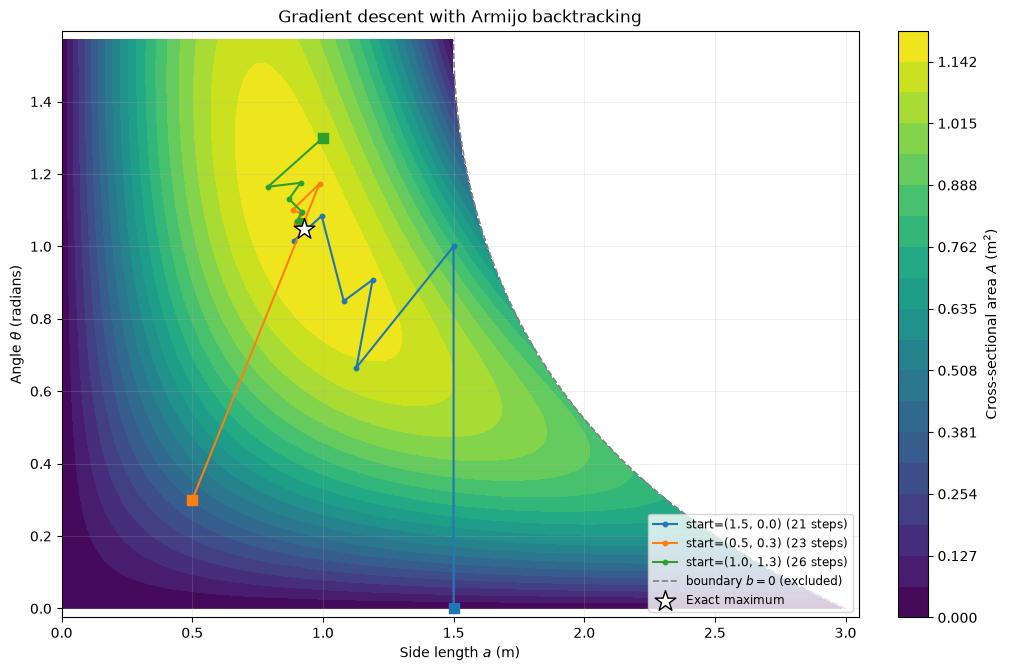

In [25]:
# Contour plot

a_vals = np.linspace(0, 3, 420)
theta_vals = np.linspace(0, np.pi / 2, 320)
AA, TT = np.meshgrid(a_vals, theta_vals)
Z = AA * (3 - AA - AA * np.sin(TT)) * np.sin(TT) + 0.5 * AA**2 * np.sin(TT) * np.cos(TT)
Z = np.ma.masked_where((AA <= 0) | (AA >= 3 / (1 + np.sin(TT))), Z)

fig, ax = plt.subplots(figsize=(10, 6.6), layout="constrained")
levels = np.linspace(0, 1.2058, 20)
ct = ax.contourf(AA, TT, Z, levels=levels)
fig.colorbar(ct, ax=ax, label=r"Cross-sectional area $A$ ($\mathrm{m}^2$)")
ax.set_ylabel(r"Angle $\theta$ (radians)")

for x0, x, path, history, status in solutions:
    (line,) = ax.plot(path[:, 0], path[:, 1], '-o', ms=3.2, lw=1.5,
                      label=f"start={x0} ({len(path)-1} steps)")
    ax.scatter(path[0, 0], path[0, 1], marker='s', s=55,
               color=line.get_color(), zorder=5)

curve = np.linspace(0, np.pi / 2, 300)
ax.plot(3 / (1 + np.sin(curve)), curve, '--', lw=1.2, color='gray',
        label=r"boundary $b=0$ (excluded)")
ax.scatter(*known_optimum, marker='*', s=245, facecolor='white',
           edgecolor='black', linewidth=1.0, zorder=7, label="Exact maximum")
ax.set_xlim(0, 3.05)
ax.set_ylim(-0.025, np.pi / 2 + 0.025)
ax.set_xlabel(r"Side length $a$ (m)")
ax.set_ylabel(r"Angle $\theta$ (radians)")
ax.set_title("Gradient descent with Armijo backtracking")
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(alpha=0.2)

plt.show()



## 5. Additional methods: fixed-rate gradient descent, momentum, and Newton's method

In [26]:
# Three additional methods: fixed-rate GD, momentum, and damped Newton

def project_feasible(x):
    theta = np.clip(x[1], 0, np.pi / 2)
    a = np.clip(x[0], 1e-10, 3 / (1 + np.sin(theta)) - 1e-10)
    return np.array([a, theta])


def fixed_gd(x0, epsilon=1e-6, alpha=0.15, max_iter=3000):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    for _ in range(max_iter):
        g = grad_f(x)
        if np.linalg.norm(g) < epsilon:
            return x, np.array(path), "converged"
        x_new = project_feasible(x - alpha * g)
        if np.array_equal(x_new, x):
            return x, np.array(path), "step_too_small"
        x = x_new
        path.append(x.copy())
    return x, np.array(path), "max_iter"


def momentum_gd(x0, epsilon=1e-6, alpha=0.11, beta=0.7, max_iter=3000):
    x = np.array(x0, dtype=float)
    v = np.zeros_like(x)
    path = [x.copy()]
    for _ in range(max_iter):
        g = grad_f(x)
        if np.linalg.norm(g) < epsilon:
            return x, np.array(path), "converged"
        v = beta * v - alpha * g
        x_new = project_feasible(x + v)
        v = x_new - x  # Reset any momentum removed by projection
        if np.array_equal(x_new, x):
            return x, np.array(path), "step_too_small"
        x = x_new
        path.append(x.copy())
    return x, np.array(path), "max_iter"


def hessian_f(x):
    a, t = x
    s, c = np.sin(t), np.cos(t)
    h11 = (2 + 2*s - c)*s
    h12 = 2*a*np.sin(2*t) + 2*a*c - a*np.cos(2*t) - 3*c
    h22 = a*(-a*s + a*np.sin(2*t) + 2*a*np.cos(2*t) + 3*s)
    return np.array([[h11, h12], [h12, h22]])


def newton_method(x0, epsilon=1e-6, max_iter=300):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    for _ in range(max_iter):
        g = grad_f(x)
        if np.linalg.norm(g) < epsilon:
            return x, np.array(path), "converged"
        H = hessian_f(x)
        d = np.linalg.solve(H, -g) if np.min(np.linalg.eigvalsh(H)) > 1e-9 else -g
        alpha = backtracking(f, grad_f, d, x)
        if alpha is None:
            return x, np.array(path), "line_search_failed"
        x_new = x + alpha * d
        if np.array_equal(x_new, x):
            return x, np.array(path), "step_too_small"
        x = x_new
        path.append(x.copy())
    return x, np.array(path), "max_iter"


# Same Armijo algorithm as Cell 01. However, here we do it without constructing a DataFrame, so that the measurement is consistent across methods
def armijo_gd(x0, epsilon=1e-6, max_iter=1000):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    for _ in range(max_iter):
        g = grad_f(x)
        norm = np.linalg.norm(g)
        if norm < epsilon:
            return x, np.array(path), "converged"
        alpha = backtracking(f, grad_f, -g / norm, x)
        if alpha is None:
            return x, np.array(path), "line_search_failed"
        x_new = x - alpha * g / norm
        if np.array_equal(x_new, x):
            return x, np.array(path), "step_too_small"
        x = x_new
        path.append(x.copy())
    return x, np.array(path), "max_iter"

methods = {
    "Armijo GD": armijo_gd,
    "Fixed GD": fixed_gd,
    "Momentum": momentum_gd,
    "Newton": newton_method,}


## 6. Compare iterations, final area, and error across solvers

In [27]:
# Compare all methods from the same three initial states
method_runs = {}
rows = []
for name, method in methods.items():
    method_runs[name] = []
    for x0 in starts:
        x, path, status = method(x0)
        method_runs[name].append((x0, x, path, status))
        rows.append({"method": name, "start": str(x0), "status": status,
                     "iterations": len(path) - 1, "final_area": area(x),
                     "position_error": np.linalg.norm(x - known_optimum)})

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False, float_format=lambda v: f"{v:.8g}"))

   method      start    status  iterations  final_area  position_error
Armijo GD (1.5, 0.0) converged          21   1.2057714   5.4763936e-07
Armijo GD (0.5, 0.3) converged          23   1.2057714   6.5266598e-07
Armijo GD (1.0, 1.3) converged          26   1.2057714   2.9687696e-07
 Fixed GD (1.5, 0.0) converged         154   1.2057714   1.7848054e-06
 Fixed GD (0.5, 0.3) converged         134   1.2057714   1.8070215e-06
 Fixed GD (1.0, 1.3) converged         136   1.2057714   1.6793893e-06
 Momentum (1.5, 0.0) converged          73   1.2057714   1.1150296e-06
 Momentum (0.5, 0.3) converged          75   1.2057714   1.0694534e-06
 Momentum (1.0, 1.3) converged          70   1.2057714   6.5263488e-07
   Newton (1.5, 0.0) converged           7   1.2057714   6.7222603e-11
   Newton (0.5, 0.3) converged           6   1.2057714   9.5132301e-11
   Newton (1.0, 1.3) converged           5   1.2057714   3.0641839e-08


## 7. Trajectory plots for the additional solvers

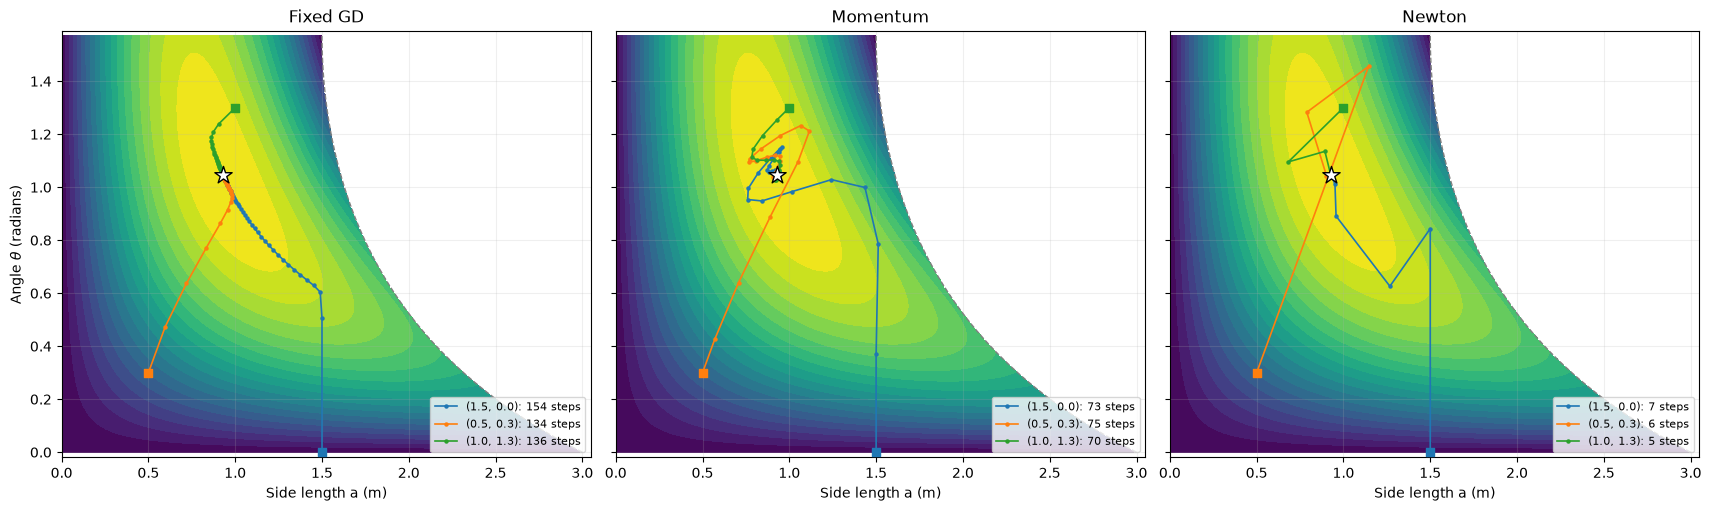

In [28]:
# Convergence paths for the three additional methods
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True,
                         layout="constrained")
for ax, name in zip(axes, ["Fixed GD", "Momentum", "Newton"]):
    ax.contourf(AA, TT, Z, levels=levels)
    for j, (x0, x, path, status) in enumerate(method_runs[name]):
        (line,) = ax.plot(path[:, 0], path[:, 1], '-o', ms=2.2, lw=1.2,
                          label=f"{x0}: {len(path)-1} steps")
        ax.scatter(*path[0], marker='s', color=line.get_color(), s=32, zorder=5)
    ax.plot(3 / (1 + np.sin(curve)), curve, '--', color='gray', lw=1)
    ax.scatter(*known_optimum, marker='*', s=170, facecolor='white',
               edgecolor='black', zorder=6)
    ax.set_title(name)
    ax.set_xlabel("Side length a (m)")
    ax.set_xlim(0, 3.05)
    ax.set_ylim(-0.02, np.pi / 2 + 0.02)
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.2)
axes[0].set_ylabel(r"Angle $\theta$ (radians)")
plt.show()

## 8. Runtime benchmarks

For each method, compare workloads and tolerances. Times are empirical, so CPU load and hardware influence the results.

In [ ]:
# Runtime benchmarking
import time

rng = np.random.default_rng(164)
bench_starts = list(starts)
for _ in range(77):
    theta = rng.uniform(0.22, 1.35)
    a = rng.uniform(0.35, 0.80) * 3 / (1 + np.sin(theta))
    bench_starts.append((a, theta))

repeats = 7
sizes = [1, 5, 10, 20, 40, 80]
tolerances = [1e-3, 1e-4, 1e-5, 1e-6]

for method in methods.values():
    method(starts[0])

def measure(method, inputs, epsilon):
    times, iterations = [], []
    for _ in range(repeats):
        t0 = time.perf_counter()
        results = [method(x0, epsilon=epsilon) for x0 in inputs]
        times.append(time.perf_counter() - t0)
        if any(status != "converged" for _, _, status in results):
            raise RuntimeError("A benchmark run did not converge")
        iterations.append(np.mean([len(path)-1 for _, path, _ in results]))
    return np.median(times), np.percentile(times, 10), np.percentile(times, 90), np.median(iterations)


scaling_rows = []
for n in sizes:
    for name, method in methods.items():
        med, p10, p90, steps = measure(method, bench_starts[:n], 1e-6)
        scaling_rows.append({"method": name, "n": n, "median_ms": med*1000,
                             "p10_ms": p10*1000, "p90_ms": p90*1000,
                             "mean_iterations": steps})
scaling_times = pd.DataFrame(scaling_rows)

tolerance_rows = []
for tol in tolerances:
    for name, method in methods.items():
        med, p10, p90, steps = measure(method, bench_starts[:10], tol)
        tolerance_rows.append({"method": name, "tolerance": tol,
                               "ms_per_solve": med*100, "mean_iterations": steps})
tolerance_times = pd.DataFrame(tolerance_rows)

print("Median runtime (ms) for 80 independent solves, tolerance=1e-6:")
print(scaling_times[scaling_times.n == 80][["method", "median_ms", "mean_iterations"]].to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print("\nMedian runtime per solve (ms), 10 starts, tolerance=1e-6:")
print(tolerance_times[tolerance_times.tolerance == 1e-6][["method", "ms_per_solve", "mean_iterations"]].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# Scaling exponent with respect to the number of independent solves
print("\nObserved workload-scaling exponent from n = 10, 20, 40, 80:")
for name in methods:
    r = scaling_times[(scaling_times.method == name) & (scaling_times.n >= 10)]
    exponent = np.polyfit(np.log(r.n), np.log(r.median_ms), 1)[0]
    print(f"{name:10s}: n^{exponent:.2f}")

Median runtime (ms) for 80 independent solves, tolerance=1e-6:
   method  median_ms  mean_iterations
Armijo GD    223.141           27.475
 Fixed GD    326.863          139.162
 Momentum    169.671           69.487
   Newton     26.704            4.912

Median runtime per solve (ms), 10 starts, tolerance=1e-6:
   method  ms_per_solve  mean_iterations
Armijo GD         2.689           28.500
 Fixed GD         4.006          143.000
 Momentum         2.169           72.500
   Newton         0.388            5.800

Observed workload-scaling exponent from n = 10, 20, 40, 80:
Armijo GD : n^0.73
Fixed GD  : n^0.91
Momentum  : n^0.97
Newton    : n^0.86


## 9. Runtime and accuracy plots

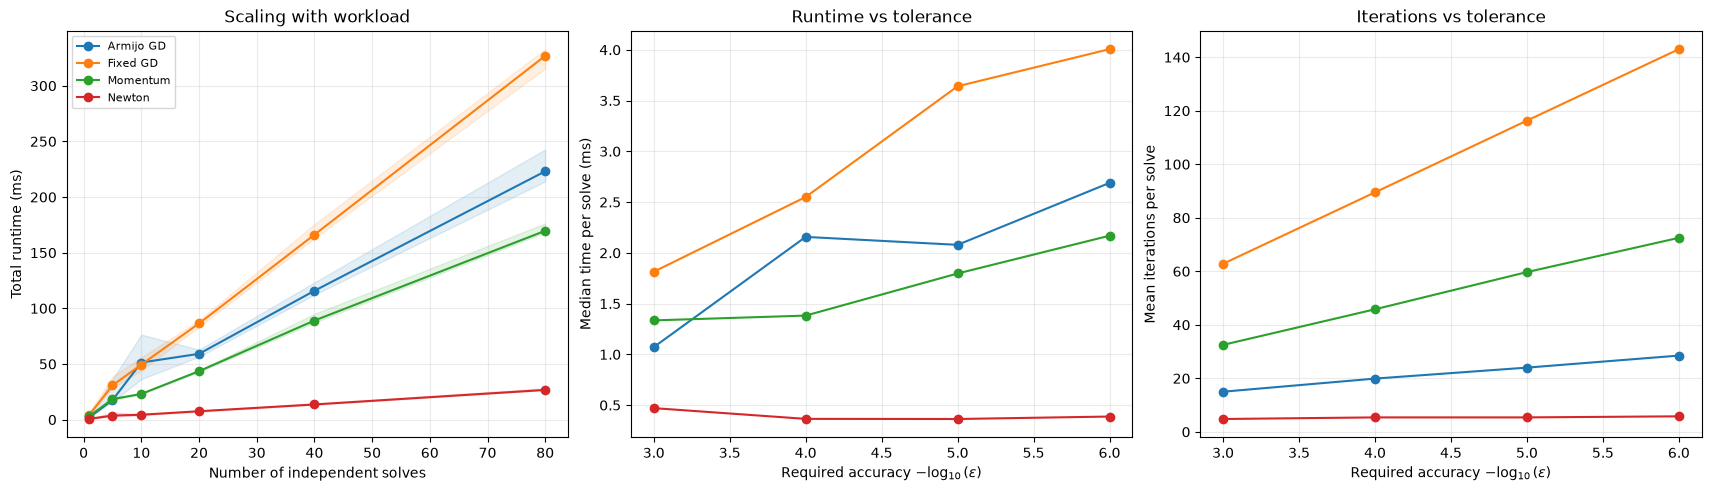

In [30]:
# Empirical runtime scaling and convergence-cost comparison
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
for name in methods:
    work = scaling_times[scaling_times.method == name]
    tol = tolerance_times[tolerance_times.method == name]
    (line,) = axes[0].plot(work.n, work.median_ms, '-o', label=name)
    axes[0].fill_between(work.n, work.p10_ms, work.p90_ms,
                         color=line.get_color(), alpha=0.12)
    axes[1].plot(-np.log10(tol.tolerance), tol.ms_per_solve, '-o', label=name)
    axes[2].plot(-np.log10(tol.tolerance), tol.mean_iterations, '-o', label=name)

axes[0].set(xlabel="Number of independent solves", ylabel="Total runtime (ms)",
            title="Scaling with workload")
axes[1].set(xlabel=r"Required accuracy $-\log_{10}(\varepsilon)$",
            ylabel="Median time per solve (ms)", title="Runtime vs tolerance")
axes[2].set(xlabel=r"Required accuracy $-\log_{10}(\varepsilon)$",
            ylabel="Mean iterations per solve", title="Iterations vs tolerance")
for ax in axes:
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
plt.show()